In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [9]:
df = pd.read_csv("c:/Users/Janvi/Downloads/uber.csv.zip")

In [10]:
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [11]:
# Remove missing values
df = df.dropna()

# Remove invalid fare amounts
df = df[df['fare_amount'] > 0]

# Remove invalid passenger counts
df = df[df['passenger_count'].between(1, 6)]

# Remove invalid geographical coordinates
df = df[
    df['pickup_longitude'].between(-180, 180) &
    df['dropoff_longitude'].between(-180, 180) &
    df['pickup_latitude'].between(-90, 90) &
    df['dropoff_latitude'].between(-90, 90)
]

print("Shape after preprocessing:", df.shape)

Shape after preprocessing: (199256, 9)


Number of outliers: 17120


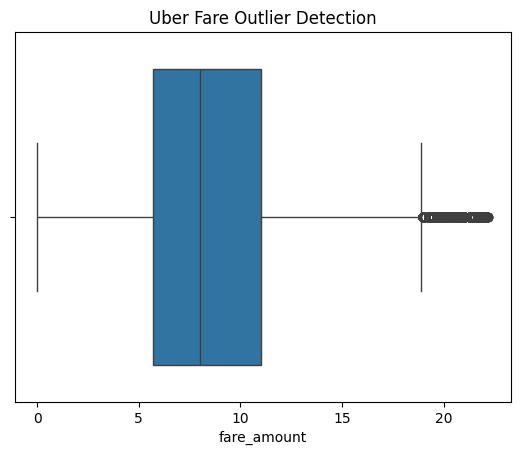

In [12]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df['fare_amount'] < lower) |
    (df['fare_amount'] > upper)
]

print("Number of outliers:", len(outliers))

# Remove fare outliers
df = df[df['fare_amount'].between(lower, upper)]

sns.boxplot(x=df['fare_amount'])
plt.title("Uber Fare Outlier Detection")
plt.show()

In [13]:
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'],
    errors='coerce',
    utc=True
)

df = df.dropna(subset=['pickup_datetime'])

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year

# Calculate distance using Haversine formula
def haversine(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2

    return 6371 * 2 * np.arcsin(np.sqrt(a))


df['distance'] = haversine(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

# Remove unrealistic zero-distance rides
df = df[df['distance'] > 0]

print(df.head())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

            pickup_datetime  pickup_longitude  pickup_latitude  \
0 2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1 2009-07-17 20:04:56+00:00        -73.994355        40.728225   
2 2009-08-24 21:45:00+00:00        -74.005043        40.740770   
3 2009-06-26 08:22:21+00:00        -73.976124        40.790844   
4 2014-08-28 17:47:00+00:00        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  hour  day  month  \
0         -73.999512         40.723217                1    19    7      5   
1         -73.994710         40.750325                1    20   17      7   
2    

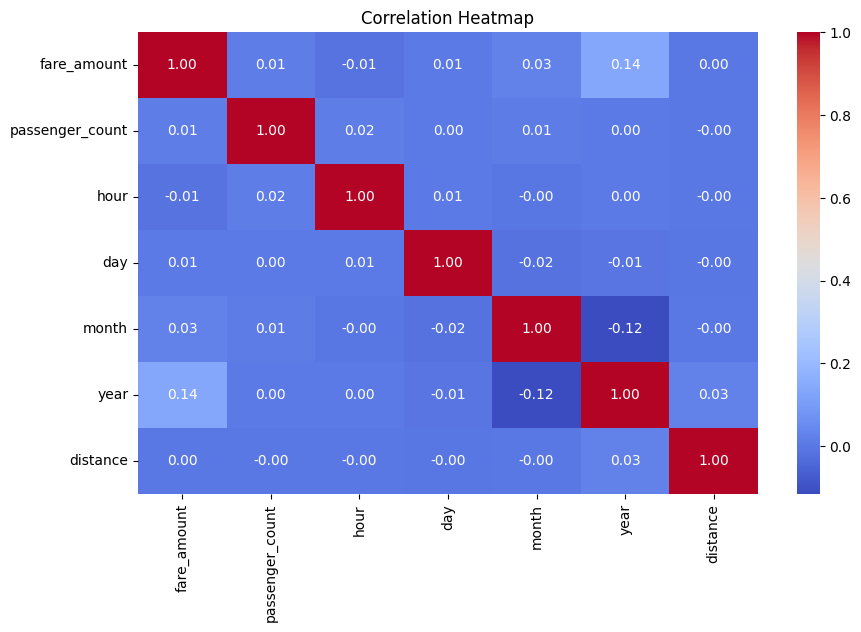

In [14]:
features = [
    'fare_amount',
    'passenger_count',
    'hour',
    'day',
    'month',
    'year',
    'distance'
]

correlation = df[features].corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [15]:
# Select input features
X = df[
    [
        'passenger_count',
        'hour',
        'day',
        'month',
        'year',
        'distance'
    ]
]

# Target variable
y = df['fare_amount']

# Use a sample for faster execution
if len(X) > 50000:
    X = X.sample(50000, random_state=42)
    y = y.loc[X.index]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40000, 6)
Testing data: (10000, 6)


In [16]:
lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Linear Regression Results")

print("R2 Score:", r2_score(y_test, y_pred_lr))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test, y_pred_lr)
))

print("MAE:", mean_absolute_error(y_test, y_pred_lr))

Linear Regression Results
R2 Score: 0.02286628800171353
RMSE: 4.078731956760704
MAE: 3.215624880680995


In [17]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest Results")

print("R2 Score:", r2_score(y_test, y_pred_rf))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
))

print("MAE:", mean_absolute_error(y_test, y_pred_rf))

Random Forest Results
R2 Score: 0.7102342731364621
RMSE: 2.2211182227799133
MAE: 1.57073119


In [18]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_rf)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_rf)
    ]
})

print(results)

               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.022866  4.078732  3.215625
1      Random Forest  0.710234  2.221118  1.570731


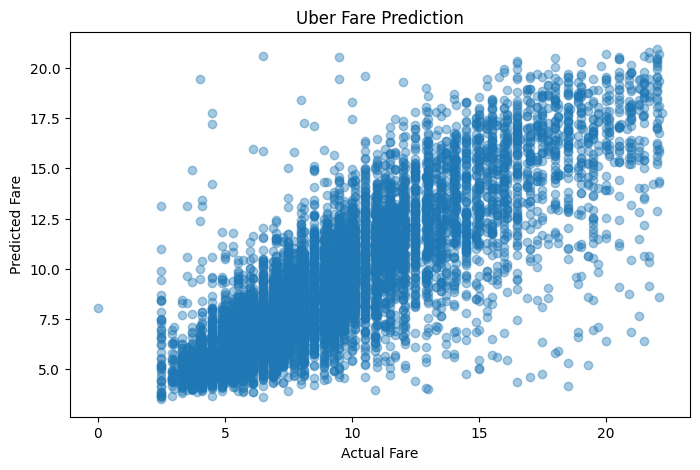

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.4
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")

plt.title("Uber Fare Prediction")

plt.show()